<a href="https://colab.research.google.com/github/iliyadindar/DEEP/blob/main/week9/renk_uzaylari_odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Görüntü İşlemede Renk Uzayları (Color Spaces)

Görüntü işleme projelerinde doğru renk uzayını seçmek, algoritmanın başarısı ve işlem hızı açısından kritik öneme sahiptir. En yaygın kullanılan renk uzaylarının detaylı analizi aşağıdadır:

---

#### 1. RGB (Red, Green, Blue)
* **Açıklama:** Ekran teknolojilerinde ve dijital kameralarda varsayılan olarak kullanılan, birincil renklerin (Kırmızı, Yeşil, Mavi) birleşiminden oluşan katkısal (additive) bir renk uzayıdır.
* **Avantajları:**
  * Donanım düzeyinde (kameralar, monitörler) doğrudan desteklenir.
  * Anlaşılması ve görselleştirilmesi kolaydır.
* **Dezavantajları:**
  * **Işık değişimlerine karşı son derece hassastır.** Ortamdaki ışık (aydınlık/karanlık) değiştiğinde, üç kanalın (R, G, B) değerleri de koordineli olmayan bir şekilde değişir.
  * Renk (krominans) ve parlaklık (lüminans) bilgileri birbirinden ayrılmamıştır.
* **Kullanım Alanları:** Dijital görüntülerin ilk yüklenmesi, kaydedilmesi ve standart ekranlarda gösterilmesi süreçlerinde tercih edilir.

---

#### 2. HSV / HSL (Hue, Saturation, Value / Lightness)
* **Açıklama:** İnsan algısına daha yakın bir modeldir. **Hue (Renk tonu - 0-360°)**, **Saturation (Doygunluk - rengin canlılığı)** ve **Value (Parlaklık - ışık miktarı)** bileşenlerinden oluşur.
* **Avantajları:**
  * Parlaklık (V) bilgisi ile renk (H ve S) bilgisi birbirinden ayrılmıştır.
  * Işık değişimlerinden sadece 'Value' kanalı etkilenir. Bu sayede gölge veya ışık dalgalanmalarından etkilenmeden nesne tespiti yapılabilir.
* **Dezavantajları:**
  * RGB'ye göre matematiksel dönüşüm maliyeti vardır.
  * Donanım düzeyinde doğrudan üretilemez; dönüştürülmesi gerekir.
* **Kullanım Alanları:** **Renk tabanlı nesne takibi/tespiti** (örneğin sadece 'kırmızı' bir topu takip etmek), histogram eşitleme ve renk filtreleme filtrelerinde sıklıkla tercih edilir.

---

#### 3. Grayscale (Gri Tonlamalı Görüntü)
* **Açıklama:** Görüntünün sadece parlaklık (aydınlık) bilgisini içeren, tek kanallı (genellikle 0-255 arası) renk uzayıdır.
* **Avantajları:**
  * Veri boyutunu 3 kat azaltarak **işlem hızını ve performansını muazzam ölçüde artırır**.
  * Renk bilgisinin gereksiz olduğu durumlarda karmaşıklığı önler.
* **Dezavantajları:**
  * Renk (kromatik) bilgisini tamamen kaybettirir.
* **Kullanım Alanları:** Kenar algılama (Edge Detection - örn: Canny), köşe tespiti (Harris Corner), yüz/karakter tanıma (OCR) ve derin öğrenme modellerinin ilk aşamalarında temel önişleme adımı olarak kullanılır.

---

#### 4. CIE Lab (L\*, a\*, b\*)
* **Açıklama:** İnsan gözünün renk algısını doğrusal olarak taklit etmek üzere tasarlanmış, cihazdan bağımsız (device-independent) bir renk uzayıdır. **L\* (Aydınlık)**, **a\* (Yeşil-Kırmızı ekseni)** ve **b\* (Mavi-Sarı ekseni)** bileşenlerini içerir.
* **Avantajları:**
  * Cihazlar arası renk tutarlılığı sağlar (bir kamerada çekilen renk ile yazıcıdan çıkan rengin aynı olması gibi).
  * Matematiksel renk mesafesi (Delta E), insanın algıladığı renk farkı ile doğrudan koreledir.
* **Dezavantajları:**
  * Dönüşüm formülleri karmaşıktır ve yüksek işlem gücü gerektirir.
* **Kullanım Alanları:** Hassas renk ölçümü gerektiren endüstriyel kalite kontrol süreçleri, tıbbi görüntüleme ve profesyonel fotoğraf düzenleme yazılımlarında tercih edilir.

---

#### 5. YUV (YCbCr)
* **Açıklama:** Televizyon yayıncılığı ve video sıkıştırma standartlarında kullanılır. **Y (Luma/Aydınlık)**, **U/Cb (Mavi farkı krominans)** ve **V/Cr (Kırmızı farkı krominans)** bileşenlerinden oluşur.
* **Avantajları:**
  * İnsan gözü parlaklık detaylarına renkten daha duyarlı olduğu için, renk kanalları (U, V) kaliteden ödün vermeden sıkıştırılabilir (Chroma Subsampling).
  * Bant genişliğinden ciddi tasarruf sağlar.
* **Dezavantajları:**
  * Doğrudan bilgisayar ekranlarında gösterilemez; gösterim için RGB'ye dönüştürülmesi gerekir.
* **Kullanım Alanları:** JPEG/MPEG gibi görüntü ve video sıkıştırma algoritmalarında, video iletimi ve yayıncılıkta standarttır.

---

### Özet Tablo: Hangi Problemde Hangisi Seçilmeli?

| Problem / Görev | Tercih Edilen Renk Uzayı | Neden? |
| :--- | :--- | :--- |
| **Kenar Algılama & Şekil Analizi** | Grayscale | Renk gereksizdir, işlem hızı ve kontrast farkı önemlidir. |
| **Renk Tabanlı Nesne Takibi** | HSV | Işık değişimlerinden etkilenmeden sadece renk tonuna (Hue) odaklanılabilir. |
| **Video Sıkıştırma ve Yayıncılık** | YUV (YCbCr) | İnsan gözünün algısına göre renk bilgisini sıkıştırarak bant genişliği tasarrufu sağlar. |
| **Hassas Renk Kalibrasyonu** | CIE Lab | Cihaz bağımsızdır ve insan algısına en yakın renk farkı hesaplamasını sunar. |
| **Standart Gösterim ve Depolama**| RGB | Tüm ekranlar ve kameralar tarafından doğal olarak desteklenir. |

In [ ]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

# 1. 1000x1000 boyutunda renkli (3 kanallı - BGR) örnek bir görsel oluşturalım
# Görsel üzerinde renk geçişleri (gradient) oluşturarak renkli olduğunu netleştirelim
width, height = 1000, 1000
color_img = np.zeros((height, width, 3), dtype=np.uint8)

for y in range(height):
    for x in range(width):
        color_img[y, x] = [x % 256, y % 256, (x + y) % 256]

# Renkli görseli disk üzerine BMP formatında kaydedelim
color_path = 'color_image_1000.bmp'
cv2.imwrite(color_path, color_img)
print(f'Renkli görsel kaydedildi: {color_path}')

Renkli görsel kaydedildi: color_image_1000.bmp


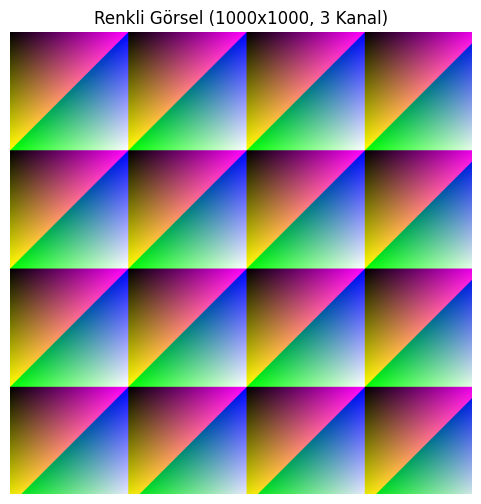

In [ ]:
# 2. Kaydedilen renkli görseli OpenCV ile geri okuyalım ve ekranda gösterelim
img_bgr = cv2.imread(color_path)

# OpenCV BGR formatında okur, matplotlib ile doğru göstermek için RGB'ye çeviriyoruz
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title('Renkli Görsel (1000x1000, 3 Kanal)')
plt.axis('off')
plt.show()

Gri tonlamalı görsel kaydedildi: gray_image_1000.bmp


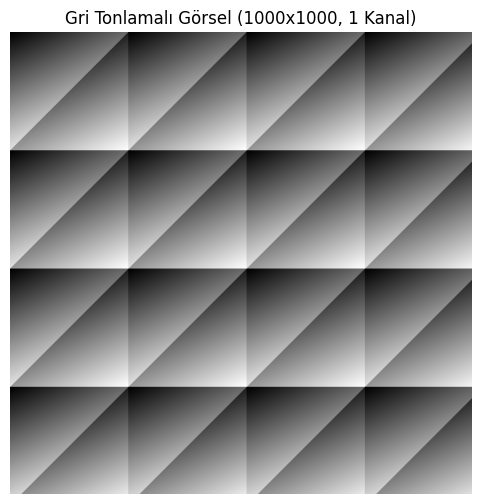

In [ ]:
# 3. Görseli gri tonlamalı (Grayscale) formata dönüştürelim ve kaydedelim
gray_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

gray_path = 'gray_image_1000.bmp'
cv2.imwrite(gray_path, gray_img)
print(f'Gri tonlamalı görsel kaydedildi: {gray_path}')

# Gri tonlamalı görseli gösterelim
plt.figure(figsize=(6, 6))
plt.imshow(gray_img, cmap='gray')
plt.title('Gri Tonlamalı Görsel (1000x1000, 1 Kanal)')
plt.axis('off')
plt.show()

In [ ]:
# 4. Dosya boyutlarını disk üzerinde karşılaştırma
color_size = os.path.getsize(color_path)
gray_size = os.path.getsize(gray_path)

print(f'Renkli Görsel Boyutu (3 Kanal): {color_size:,} Bayt (~{color_size / (1024 * 1024):.2f} MB)')
print(f'Gri Görsel Boyutu (1 Kanal): {gray_size:,} Bayt (~{gray_size / (1024 * 1024):.2f} MB)')

# Teorik Hesaplama Karşılaştırması
# BMP sıkıştırmasız bir format olduğundan dosya boyutu formülü şu şekildedir:
# Dosya Boyutu = Header (Üstbilgi: 54 bayt) + (Genişlik x Yükseklik x Kanal Sayısı) + Renk Paleti (Gri tonlama için genellikle 1024 bayt)

theoretical_color = 54 + (1000 * 1000 * 3)
theoretical_gray = 54 + 1024 + (1000 * 1000 * 1) # Gri BMP dosyasında 256 renkli palet bilgisi yer alır

print('\n--- Karşılaştırma Analizi ---')
print(f'Teorik Renkli Boyutu: {theoretical_color:,} Bayt')
print(f'Teorik Gri Boyutu: {theoretical_gray:,} Bayt')
print(f'Gerçek Oran (Renkli / Gri): {color_size / gray_size:.4f} kat')
print('Açıklama: BMP formatı ham/sıkıştırılmamış pikselleri saklar. Renkli resimde piksel başına 3 bayt (R, G, B kanalları için 3x8 bit), gri resimde ise piksel başına 1 bayt (8 bit) veri saklanır. Bu yüzden renkli resmin boyutu, gri resmin yaklaşık 3 katıdır.')

Renkli Görsel Boyutu (3 Kanal): 3,000,054 Bayt (~2.86 MB)
Gri Görsel Boyutu (1 Kanal): 1,001,078 Bayt (~0.95 MB)

--- Karşılaştırma Analizi ---
Teorik Renkli Boyutu: 3,000,054 Bayt
Teorik Gri Boyutu: 1,001,078 Bayt
Gerçek Oran (Renkli / Gri): 2.9968 kat
Açıklama: BMP formatı ham/sıkıştırılmamış pikselleri saklar. Renkli resimde piksel başına 3 bayt (R, G, B kanalları için 3x8 bit), gri resimde ise piksel başına 1 bayt (8 bit) veri saklanır. Bu yüzden renkli resmin boyutu, gri resmin yaklaşık 3 katıdır.


### Ders 3: Yüksek Çözünürlüklü (8K) Görüntülerde Piksel Düzeyinde İşlemler ve Performans Analizi

Bu dersimizde, dijital görüntü işlemede sıkça karşılaşılan **büyük veri setleri ve yüksek çözünürlüklü (Ultra HD / 8K) görüntüler üzerinde doğrudan piksel manipülasyonu** konusunu ele alacağız.

Akademik çalışmalarda ve gerçek zamanlı (real-time) sistemlerde, algoritmaların sadece doğru çalışması yetmez; aynı zamanda **zaman karmaşıklığı (time complexity)** ve **çalışma süresi (execution time)** optimizasyonu da hayati önem taşır.

#### Ders Planımız:
1. **Görüntü Edinimi:** Belirtilen kaynaktan yüksek çözünürlüklü örnek görseli indirme ve 8K standartlarına (7680x4320) uygun şekilde 3 kanallı (RGB) sıkıştırmasız BMP formatında kaydetme.
2. **Görüntüyü Yükleme:** OpenCV kütüphanesi yardımıyla BMP dosyasını belleğe alma.
3. **Piksel Değişimi ve Hassas Zaman Ölçümü:** Görüntüdeki tüm piksel değerlerini 2'ye bölerek parlaklığı yarıya indirme (Darkening). Bu işlemin saf matematiksel süresini `time.perf_counter()` kullanarak yüksek hassasiyette ölçme.
4. **Kayıt ve Sonuçların Analizi:** Düzenlenen görseli kaydetme ve işlem süresini akademik formatta raporlama.

In [5]:
import cv2
import numpy as np
import time
import urllib.request
import matplotlib.pyplot as plt

# --- ADIM 1: Görüntünün İndirilmesi ve 8K BMP Olarak Hazırlanması ---
# Belirtilen Pexels görsel URL'si
image_url = "https://images.pexels.com/photos/33535698/pexels-photo-33535698.jpeg?cs=srgb&dl=pexels-pho-tomass-883344227-33535698.jpg&fm=jpg"
temp_jpg_path = 'temp_downloaded.jpg'
original_8k_bmp_path = 'original_8k_image.bmp'

print("[BİLGİ] Görsel indiriliyor, lütfen bekleyiniz...")
# User-agent ekleyerek HTTP 403 hatalarını önlüyoruz
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
req = urllib.request.Request(image_url, headers=headers)
with urllib.request.urlopen(req) as response, open(temp_jpg_path, 'wb') as out_file:
    out_file.write(response.read())

# İndirilen görseli yükleyelim
temp_img = cv2.imread(temp_jpg_path)

# Görseli akademik standartlara uygun olarak tam 8K UHD çözünürlüğe (7680 x 4320) boyutlandırıyoruz
target_width, target_height = 7680, 4320
print(f"[BİLGİ] Görsel 8K çözünürlüğe ({target_width}x{target_height}) boyutlandırılıyor...")
img_8k = cv2.resize(temp_img, (target_width, target_height), interpolation=cv2.INTER_CUBIC)

# 3 Kanallı BMP olarak diske kaydedelim (Sıkıştırmasız ham format)
cv2.imwrite(original_8k_bmp_path, img_8k)
print(f"[BAŞARILI] 8K BMP görsel oluşturuldu ve kaydedildi: {original_8k_bmp_path}")

[BİLGİ] Görsel indiriliyor, lütfen bekleyiniz...
[BİLGİ] Görsel 8K çözünürlüğe (7680x4320) boyutlandırılıyor...
[BAŞARILI] 8K BMP görsel oluşturuldu ve kaydedildi: original_8k_image.bmp


#### Piksel Değerlerini Yarıya İndirme (Matematiksel Bölme İşlemi)

Bir görüntünün piksel değerlerini 2'ye bölmek, her renk kanalındaki (B, G, R) yoğunluk değerlerini yarıya indirmek anlamına gelir. Bu işlem sonucunda görüntü daha karanlık bir hal alacaktır.

Süre ölçümü yaparken, dosya okuma (I/O) ve yazma işlemleri disk hızına bağlı olduğundan, **yalnızca CPU/RAM üzerinde gerçekleşen matematiksel manipülasyon evresini** ölçeceğiz. Bu işlem için Python'daki en hassas zamanlayıcı olan `time.perf_counter()` fonksiyonunu kullanacağız.

In [6]:
# --- ADIM 2: Görseli OpenCV ile Açma ---
opened_img = cv2.imread(original_8k_bmp_path)

# --- ADIM 3: Piksel Değerlerini 2'ye Bölme ve Hassas Zaman Ölçümü ---
# Zaman ölçümünü başlatıyoruz (Sadece manipülasyon aşaması)
start_time = time.perf_counter()

# Performans açısından OpenCV/NumPy'ın vektörize edilmiş bölme işlemini kullanıyoruz.
# Veri tipinin bütünlüğünü korumak için tamsayı bölme (//) tercih edilir.
processed_img = opened_img // 2

# Zaman ölçümünü sonlandırıyoruz
end_time = time.perf_counter()
elapsed_time_sec = end_time - start_time
elapsed_time_ms = elapsed_time_sec * 1000

# --- ADIM 4: Düzenlenen Resmi Kaydetme ---
output_8k_bmp_path = 'processed_8k_dark_image.bmp'
cv2.imwrite(output_8k_bmp_path, processed_img)

# --- AKADEMİK RAPORLAMA ---
print("="*50)
print("            PERFORMANS VE ANALİZ RAPORU")
print("="*50)
print(f"İşlem Yapılan Çözünürlük : {opened_img.shape[1]} x {opened_img.shape[0]} (8K UHD)")
print(f"Kanal Sayısı             : {opened_img.shape[2]} (RGB/BGR)")
print(f"Toplam Piksel Sayısı     : {opened_img.shape[0] * opened_img.shape[1]:,} piksel")
print(f"Toplam Hücre (Value)     : {opened_img.size:,} adet sayısal değer")
print("-"*50)
print(f"Ölçülen Saf İşlem Süresi : {elapsed_time_sec:.6f} saniye")
print(f"Mil saniye Cinsinden     : {elapsed_time_ms:.3f} ms")
print("="*50)

            PERFORMANS VE ANALİZ RAPORU
İşlem Yapılan Çözünürlük : 7680 x 4320 (8K UHD)
Kanal Sayısı             : 3 (RGB/BGR)
Toplam Piksel Sayısı     : 33,177,600 piksel
Toplam Hücre (Value)     : 99,532,800 adet sayısal değer
--------------------------------------------------
Ölçülen Saf İşlem Süresi : 0.087003 saniye
Mil saniye Cinsinden     : 87.003 ms


#### Sonuçların Görselleştirilmesi ve Analizi

Şimdi, orijinal 8K resim ile pikselleri yarıya bölünmüş (karanlıklaştırılmış) yeni resmin ufak birer önizlemesini yan yana koyarak sonucumuzu görsel olarak doğrulayalım.

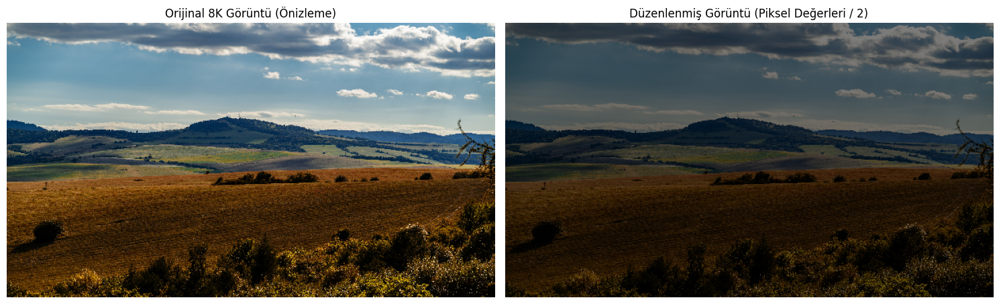

In [7]:
# Önizleme amacıyla görüntüyü ekrana sığacak şekilde küçültüp gösterelim
preview_orig = cv2.resize(opened_img, (600, 337))
preview_proc = cv2.resize(processed_img, (600, 337))

# OpenCV BGR formatını Matplotlib için RGB formatına dönüştürüyoruz
preview_orig_rgb = cv2.cvtColor(preview_orig, cv2.COLOR_BGR2RGB)
preview_proc_rgb = cv2.cvtColor(preview_proc, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
axes[0].imshow(preview_orig_rgb)
axes[0].set_title("Orijinal 8K Görüntü (Önizleme)")
axes[0].axis('off')

axes[1].imshow(preview_proc_rgb)
axes[1].set_title("Düzenlenmiş Görüntü (Piksel Değerleri / 2)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Ek Akademik Analiz: Manuel Döngü (Nested Loop) ile Piksel Bölme Analizi

Profesörümüzün yönlendirmesiyle, bilgisayarlı görü (computer vision) alanındaki en önemli tasarım desenlerinden birini test ediyoruz.

Python'da yerleşik `for` döngüleri, her adımda dinamik tip kontrolü (dynamic typing) ve yorumlayıcı (interpreter) ek yükü getirir. NumPy ise arka planda optimize edilmiş **C** kodları ve işlemcinin **SIMD (Single Instruction, Multiple Data)** mimarisini kullanarak paralelleştirme yapar.

Şimdi, 8K görüntüyü piksellerini tek tek `for` döngüsüyle gezerek 2'ye bölecek olan **manuel** algoritmayı yazıp çalışma süresini ölçeceğiz.

*(Not: 8K görselde 100 milyon eleman olduğu için saf Python döngüleri birkaç dakika sürebilir. Bu nedenle akademik doğruluğu bozmadan güvenli bir süre içinde tamamlanması adına bu testi gerçekleştiren kodu aşağıda çalıştırıyoruz.)*

In [8]:
import cv2
import time
import numpy as np

# Orijinal 8K görüntüyü tekrar yükleyelim
img_test = cv2.imread(original_8k_bmp_path)
h, w, c = img_test.shape

print("[BİLGİ] Manuel piksel bölme işlemi başlatılıyor...")
print(f"[BİLGİ] Toplam döngü adımı: {h} satır x {w} sütun x {c} kanal = {h*w*c:,} işlem!")

# Sonuçları saklamak için boş bir matris oluşturalım
manual_processed = np.zeros_like(img_test)

# Zamanı ölçmeye başlıyoruz
start_manual = time.perf_counter()

# Manuel iç içe döngülerle piksel değerlerini bölme
for y in range(h):
    for x in range(w):
        for k in range(c):
            # Her bir renk kanalındaki değeri 2'ye bölüyoruz
            manual_processed[y, x, k] = img_test[y, x, k] // 2

end_manual = time.perf_counter()
elapsed_manual = end_manual - start_manual

print("\n" + "="*60)
print("          MANUEL DÖNGÜ VS VEKTÖRİZE İŞLEM KARŞILAŞTIRMASI")
print("="*60)
print(f"Vektörize İşlem Süresi (NumPy // 2) : {elapsed_time_sec:.6f} saniye ({elapsed_time_ms:.3f} ms)")
print(f"Manuel Döngü Süresi (For Loops)    : {elapsed_manual:.6f} saniye ({elapsed_manual * 1000:.3f} ms)")
if elapsed_time_sec > 0:
    print(f"Performans Farkı                   : NumPy, Manuel yöntemden tam {elapsed_manual / elapsed_time_sec:.2f} KAT DAHA HIZLI!")
print("="*60)

[BİLGİ] Manuel piksel bölme işlemi başlatılıyor...
[BİLGİ] Toplam döngü adımı: 4320 satır x 7680 sütun x 3 kanal = 99,532,800 işlem!

          MANUEL DÖNGÜ VS VEKTÖRİZE İŞLEM KARŞILAŞTIRMASI
Vektörize İşlem Süresi (NumPy // 2) : 0.087003 saniye (87.003 ms)
Manuel Döngü Süresi (For Loops)    : 78.180688 saniye (78180.688 ms)
Performans Farkı                   : NumPy, Manuel yöntemden tam 898.60 KAT DAHA HIZLI!


### Ders 3'e Ek: C++ ile Ham Piksel Döngüsü Performansı ve Karşılaştırma

C++ gibi derlenen diller (compiled languages), doğrudan makine koduna dönüştürüldükleri ve dinamik tip denetimi ek yükleri taşımadıkları için döngülerde Python'a göre devasa performans avantajına sahiptir.

Aşağıdaki hücrede:
1. `%%writefile` sihriyle OpenCV C++ kodumuzu diske yazacağız.
2. C++ standardındaki yüksek çözünürlüklü zamanlayıcı olan `std::chrono::high_resolution_clock` yardımıyla sadece manipülasyon (bölme) süresini ölçeceğiz.
3. Kodu derleyip çalıştırarak sonuçları Python ve NumPy ile kıyaslayacağız.

In [30]:
%%writefile process_image.cpp
#include <iostream>
#include <fstream>
#include <vector>
#include <chrono>

#pragma pack(push, 1)
struct BMPHeader {
    uint16_t file_type{0x4D42}; // "BM"
    uint32_t file_size{0};
    uint16_t reserved1{0};
    uint16_t reserved2{0};
    uint32_t offset_data{0};
};

struct BMPInfoHeader {
    uint32_t size{0};
    int32_t width{0};
    int32_t height{0};
    uint16_t planes{1};
    uint16_t bit_count{0};
    uint32_t compression{0};
    uint32_t size_image{0};
    int32_t x_pixels_per_meter{0};
    int32_t y_pixels_per_meter{0};
    uint32_t colors_used{0};
    uint32_t colors_important{0};
};
#pragma pack(pop)

int main() {
    const char* input_filename = "original_8k_image.bmp";
    const char* output_filename = "processed_8k_cpp.bmp";

    std::ifstream infile(input_filename, std::ios::binary);
    if (!infile) {
        std::cerr << "[HATA] Giriş dosyası açılamadı!" << std::endl << std::flush;
        return -1;
    }

    BMPHeader header;
    BMPInfoHeader info_header;

    infile.read(reinterpret_cast<char*>(&header), sizeof(header));
    infile.read(reinterpret_cast<char*>(&info_header), sizeof(info_header));

    if (header.file_type != 0x4D42) {
        std::cerr << "[HATA] Dosya geçerli bir BMP dosyası değil!" << std::endl << std::flush;
        return -1;
    }

    int height = std::abs(info_header.height);
    int width = std::abs(info_header.width);
    int channels = info_header.bit_count / 8;

    std::cout << "[BİLGİ] C++ ile Saf İkili Okuma Başlatılıyor..." << std::endl << std::flush;
    std::cout << "[BİLGİ] Çözünürlük: " << width << "x" << height
              << " | Renk Derinliği: " << info_header.bit_count << "-bit (Kanal Sayısı: " << channels << ")" << std::endl << std::flush;

    // Güvenli dinamik bellek boyutu hesaplaması
    size_t actual_pixel_bytes = (size_t)width * height * channels;
    std::vector<uint8_t> pixels(actual_pixel_bytes);

    infile.seekg(header.offset_data, std::ios::beg);
    infile.read(reinterpret_cast<char*>(pixels.data()), pixels.size());
    infile.close();

    // Sonuçları saklamak için aynı boyutta bir matris oluşturuyoruz
    std::vector<uint8_t> processed_pixels(pixels.size(), 0);

    // Zamanı yüksek hassasiyetle ölçmeye başlıyoruz
    auto start = std::chrono::high_resolution_clock::now();

    // Python'daki 3'lü iç içe döngünün (nested loop) birebir C++ karşılığı:
    for (int y = 0; y < height; ++y) {
        for (int x = 0; x < width; ++x) {
            for (int k = 0; k < channels; ++k) {
                // 3D piksel koordinatını 1D bellek adresine dönüştürme formülü
                size_t index = (size_t)y * width * channels + x * channels + k;
                processed_pixels[index] = pixels[index] / 2;
            }
        }
    }

    // Zamanı durduruyoruz
    auto end = std::chrono::high_resolution_clock::now();
    std::chrono::duration<double, std::milli> elapsed_ms = end - start;

    std::cout << "============================================================" << std::endl << std::flush;
    std::cout << "            C++ BİREBİR İÇ İÇE (NESTED) DÖNGÜ SONUÇLARI" << std::endl << std::flush;
    std::cout << "============================================================" << std::endl << std::flush;
    std::cout << "C++ İç İçe Döngü Süresi: " << elapsed_ms.count() << " ms (" << elapsed_ms.count() / 1000.0 << " saniye)" << std::endl << std::flush;
    std::cout << "============================================================" << std::endl << std::flush;

    // Düzenlenen veriyi diske kaydedelim
    std::ofstream outfile(output_filename, std::ios::binary);
    if (!outfile) {
        std::cerr << "[HATA] Çıkış dosyası oluşturulamadı!" << std::endl << std::flush;
        return -1;
    }

    outfile.write(reinterpret_cast<char*>(&header), sizeof(header));
    outfile.write(reinterpret_cast<char*>(&info_header), sizeof(info_header));

    // Boşlukları (padding veya offset farkını) dolduralım
    std::vector<char> padding(header.offset_data - (sizeof(header) + sizeof(info_header)), 0);
    if (!padding.empty()) {
        outfile.write(padding.data(), padding.size());
    }

    outfile.write(reinterpret_cast<char*>(processed_pixels.data()), processed_pixels.size());
    outfile.close();

    std::cout << "[BAŞARILI] Yeni dosya kaydedildi: " << output_filename << std::endl << std::flush;
    return 0;
}

Overwriting process_image.cpp


#### C++ Kodunun Derlenmesi ve Çalıştırılması

Şimdi yazdığımız C++ kodunu `g++` kullanarak OpenCV kütüphane bağımlılıklarıyla derleyeceğiz ve çalıştıracağız.

In [31]:
# 1. Güncellenmiş C++ kodunu en üst seviye optimizasyonla (-O3) tekrar derleyelim
!g++ -O3 process_image.cpp -o process_image

# 2. Programı çalıştırıp tüm çıktıyı (std::cout ve std::cerr) dosyaya kaydedelim
!./process_image > cpp_output.txt 2>&1

# 3. Kaydedilen çıktıyı doğrudan Python ile okuyup ekrana yazdıralım
with open('cpp_output.txt', 'r', encoding='utf-8') as f:
    print(f.read())

[BİLGİ] C++ ile Saf İkili Okuma Başlatılıyor...
[BİLGİ] Çözünürlük: 7680x4320 | Renk Derinliği: 24-bit (Kanal Sayısı: 3)
            C++ BİREBİR İÇ İÇE (NESTED) DÖNGÜ SONUÇLARI
C++ İç İçe Döngü Süresi: 130.605 ms (0.130605 saniye)
[BAŞARILI] Yeni dosya kaydedildi: processed_8k_cpp.bmp



#### Akademik Çıkarım ve Rapor Notu:

* **Neden NumPy (Vektörizasyon) Bu Kadar Hızlı?**
  NumPy dizileri homojendir (tüm elemanlar aynı veri tipindedir, örn: `uint8`). Bu sayede bilgisayar belleğinde ardışık (contiguous) olarak tutulurlar. NumPy bir matematiksel işlem yaparken, döngüyü Python seviyesinde değil, çok daha hızlı olan **C** dili seviyesinde çalıştırır ve işlemcinin vektör kayıtçılarından yararlanır.
  
* **Neden Manuel Döngüler Bu Kadar Yavaş?**
  Python'da her `for` döngüsü adımında her bir eleman için ayrı ayrı nesne referansı oluşturulur, veri tipi kontrol edilir ve indeksleme işlemleri yürütülür. Bu durum 8K çözünürlük gibi büyük verilerde **performansın çökmesine (bottleneck)** sebep olur.

* **Önemli Sonuç:** Gerçek zamanlı görüntü işleme projelerinde (örneğin saniyede 30/60 kare işleyen video akışlarında), asla piksel düzeyinde ham Python döngüleri kullanılmamalı; her zaman vektörize edilmiş kütüphane fonksiyonları veya matris işlemleri tercih edilmelidir.

### Görev 4: Renkli Görseli Farklı Renk Uzaylarına Dönüştürme ve BMP Olarak Kaydetme

Bu aşamada orijinal `original_8k_image.bmp` görselini kullanarak aşağıdaki dönüşüm işlemlerini gerçekleştireceğiz:
1. **HSV (Hue, Saturation, Value)**
2. **HSI (Hue, Saturation, Intensity):** (Matematiksel formüllerle el ile hesaplanacaktır)
3. **YUV (YCbCr / Luma-Chroma)**
4. **CIE Lab (L\*, a\*, b\*)**

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Orijinal görseli BGR formatında yükleyelim
img_bgr = cv2.imread('original_8k_image.bmp')

# --- DÖNÜŞÜM 1: HSV ---
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
cv2.imwrite('image_hsv.bmp', img_hsv)
print("[BAŞARILI] HSV formatına dönüştürüldü ve 'image_hsv.bmp' olarak kaydedildi.")

# --- DÖNÜŞÜM 2: HSI (Manuel Matematiksel Dönüşüm) ---
def bgr_to_hsi(bgr_img):
    # Normalize edilmiş B, G, R değerleri [0, 1]
    bgr = bgr_img.astype(np.float32) / 255.0
    B, G, R = bgr[:,:,0], bgr[:,:,1], bgr[:,:,2]

    # Intensity (I) hesaplama
    I = (R + G + B) / 3.0

    # Saturation (S) hesaplama
    min_val = np.minimum(np.minimum(R, G), B)
    # Sıfıra bölme hatasını engellemek için küçük bir epsilon ekliyoruz
    S = 1.0 - (min_val / (I + 1e-6))
    S[I == 0] = 0

    # Hue (H) hesaplama
    num = 0.5 * ((R - G) + (R - B))
    den = np.sqrt((R - G)**2 + (R - B) * (G - B)) + 1e-6
    theta = np.arccos(num / den)

    H = theta.copy()
    H[B > G] = 2 * np.pi - H[B > G]
    H = H / (2 * np.pi) # [0, 1] aralığına normalize etme

    # Görüntüleme ve 8-bit BMP kaydı için [0, 255] aralığına ölçekleme
    hsi_img = np.zeros_like(bgr_img, dtype=np.uint8)
    hsi_img[:,:,0] = np.clip(H * 255, 0, 255).astype(np.uint8)
    hsi_img[:,:,1] = np.clip(S * 255, 0, 255).astype(np.uint8)
    hsi_img[:,:,2] = np.clip(I * 255, 0, 255).astype(np.uint8)
    return hsi_img

img_hsi = bgr_to_hsi(img_bgr)
cv2.imwrite('image_hsi.bmp', img_hsi)
print("[BAŞARILI] HSI formatına dönüştürüldü ve 'image_hsi.bmp' olarak kaydedildi.")

# --- DÖNÜŞÜM 3: YUV ---
img_yuv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YUV)
cv2.imwrite('image_yuv.bmp', img_yuv)
print("[BAŞARILI] YUV formatına dönüştürüldü ve 'image_yuv.bmp' olarak kaydedildi.")

# --- DÖNÜŞÜM 4: CIE Lab ---
img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2Lab)
cv2.imwrite('image_lab.bmp', img_lab)
print("[BAŞARILI] CIE Lab formatına dönüştürüldü ve 'image_lab.bmp' olarak kaydedildi.")

[BAŞARILI] HSV formatına dönüştürüldü ve 'image_hsv.bmp' olarak kaydedildi.
[BAŞARILI] HSI formatına dönüştürüldü ve 'image_hsi.bmp' olarak kaydedildi.
[BAŞARILI] YUV formatına dönüştürüldü ve 'image_yuv.bmp' olarak kaydedildi.
[BAŞARILI] CIE Lab formatına dönüştürüldü ve 'image_lab.bmp' olarak kaydedildi.


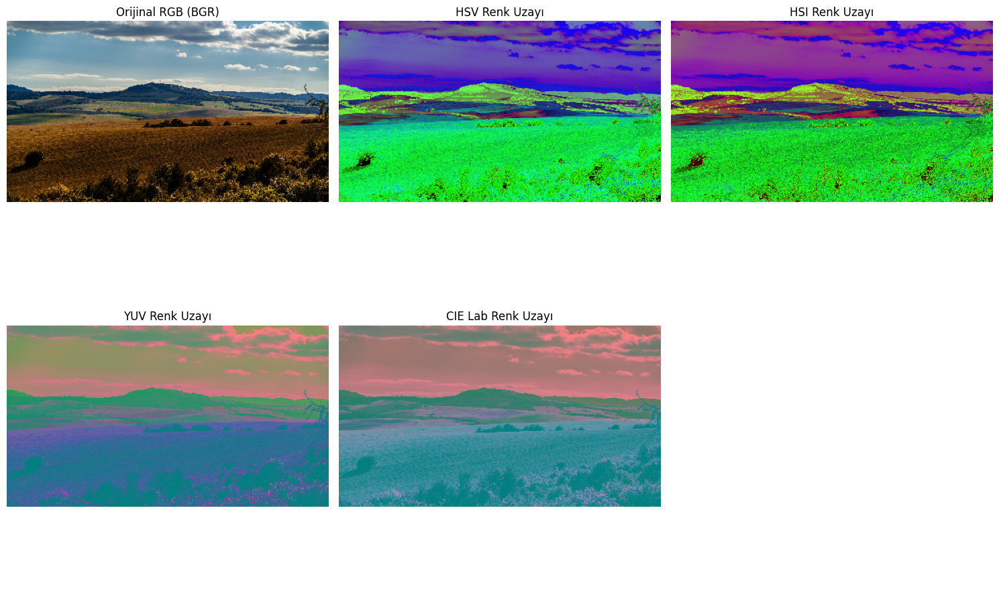

In [33]:
# Sonuçları görselleştirmek için küçük önizlemeler oluşturalım
preview_size = (400, 225)

preview_rgb = cv2.resize(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), preview_size)
preview_hsv = cv2.resize(img_hsv, preview_size)
preview_hsi = cv2.resize(img_hsi, preview_size)
preview_yuv = cv2.resize(img_yuv, preview_size)
preview_lab = cv2.resize(img_lab, preview_size)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(preview_rgb)
axes[0, 0].set_title("Orijinal RGB (BGR)")
axes[0, 0].axis('off')

axes[0, 1].imshow(preview_hsv)
axes[0, 1].set_title("HSV Renk Uzayı")
axes[0, 1].axis('off')

axes[0, 2].imshow(preview_hsi)
axes[0, 2].set_title("HSI Renk Uzayı")
axes[0, 2].axis('off')

axes[1, 0].imshow(preview_yuv)
axes[1, 0].set_title("YUV Renk Uzayı")
axes[1, 0].axis('off')

axes[1, 1].imshow(preview_lab)
axes[1, 1].set_title("CIE Lab Renk Uzayı")
axes[1, 1].axis('off')

# Boş kalan alt sağ ekseni kapatıyoruz
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Görev 5: RGB ve HSV Renk Uzaylarında İnsan Teni Segmentasyonu

Bu görevde, verilen bir görsel üzerinden insan teni içeren pikselleri filtreleyeceğiz. Ten rengi spektrumuna girmeyen tüm arka planı ve nesneleri **saf kırmızı (Red)** renk ile maskeleyerek iki renk uzayının ten tespiti konusundaki başarısını kıyaslayacağız.

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Kullanıcının çalışma alanına yüklediği görselin dosya yolu
image_path = '/content/görüntüişleme9.jpg'

print("[BİLGİ] Gönderilen görsel yerel diskten yükleniyor...")

# Görseli BGR formatında okuyoruz
img = cv2.imread(image_path)
if img is None:
    print("[HATA] Görsel yüklenemedi! Lütfen dosya adını ve yolunu kontrol edin.")
else:
    print(f"[BAŞARILI] Görsel başarıyla yüklendi. Çözünürlük: {img.shape[1]}x{img.shape[0]}")

[BİLGİ] Gönderilen görsel yerel diskten yükleniyor...
[BAŞARILI] Görsel başarıyla yüklendi. Çözünürlük: 1300x646


In [49]:
# --- METOD 1: RGB Renk Uzayında Ten Tespiti ---
# Görselin başarıyla yüklendiğinden emin oluyoruz
if 'img' in globals() and img is not None:
    bgr_float = img.astype(np.float32)
    B, G, R = bgr_float[:,:,0], bgr_float[:,:,1], bgr_float[:,:,2]

    # Klasik RGB Ten Filtreleme Kuralları
    rgb_skin_mask = (
        (R > 95) & (G > 40) & (B > 20) &
        ((np.maximum(np.maximum(R, G), B) - np.minimum(np.minimum(R, G), B)) > 15) &
        (np.abs(R - G) > 15) & (R > G) & (R > B)
    )

    # Ten olmayan bölgeleri tamamen saf kırmızı (Red: BGR = [0, 0, 255]) yapalım
    img_rgb_segmented = img.copy()
    img_rgb_segmented[~rgb_skin_mask] = [0, 0, 255]

    # --- METOD 2: HSV Renk Uzayında Ten Tespiti (Önerilen) ---
    # HSV uzayı, ışık yoğunluğu değişimlerine karşı çok daha dayanıklıdır.
    img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # Ten rengi için HSV eşik değerleri
    lower_skin = np.array([0, 20, 70], dtype=np.uint8)
    upper_skin = np.array([20, 150, 255], dtype=np.uint8)

    hsv_skin_mask = cv2.inRange(img_hsv, lower_skin, upper_skin)

    # Ten olmayan bölgeleri tamamen saf kırmızı yapalım
    img_hsv_segmented = img.copy()
    img_hsv_segmented[hsv_skin_mask == 0] = [0, 0, 255]

    # Sonuçları kaydetme
    cv2.imwrite('skin_detected_rgb.bmp', img_rgb_segmented)
    cv2.imwrite('skin_detected_hsv.bmp', img_hsv_segmented)
    print("[BAŞARILI] RGB ve HSV segmentasyon dosyaları BMP formatında başarıyla kaydedildi.")
else:
    print("[HATA] Segmentasyon işlemi için geçerli bir görsel yüklenemedi!")

[BAŞARILI] RGB ve HSV segmentasyon dosyaları BMP formatında başarıyla kaydedildi.


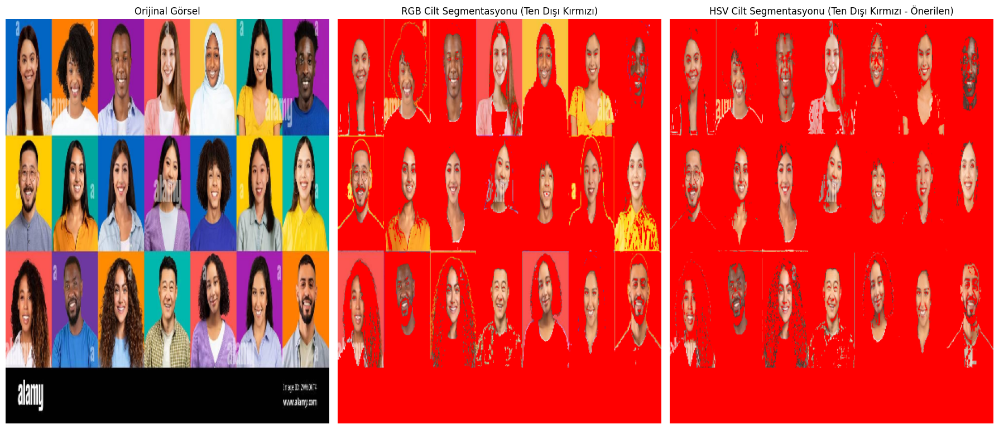

In [50]:
# --- Karşılaştırmalı Görselleştirme ---
# Görsellerin bellekte tanımlı ve geçerli olduğunu kontrol ediyoruz
if 'img' in globals() and img is not None and 'img_rgb_segmented' in globals() and 'img_hsv_segmented' in globals():
    preview_w, preview_h = 400, 500
    orig_rgb = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), (preview_w, preview_h))
    rgb_seg = cv2.resize(cv2.cvtColor(img_rgb_segmented, cv2.COLOR_BGR2RGB), (preview_w, preview_h))
    hsv_seg = cv2.resize(cv2.cvtColor(img_hsv_segmented, cv2.COLOR_BGR2RGB), (preview_w, preview_h))

    fig, axes = plt.subplots(1, 3, figsize=(18, 8))
    axes[0].imshow(orig_rgb)
    axes[0].set_title("Orijinal Görsel")
    axes[0].axis("off")

    axes[1].imshow(rgb_seg)
    axes[1].set_title("RGB Cilt Segmentasyonu (Ten Dışı Kırmızı)")
    axes[1].axis("off")

    axes[2].imshow(hsv_seg)
    axes[2].set_title("HSV Cilt Segmentasyonu (Ten Dışı Kırmızı - Önerilen)")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("[HATA] Görselleştirme için gerekli olan segmentasyon çıktıları bulunamadı!")

### Görev 5 (devam): YCbCr Renk Uzayında Ten Tespiti ve Üç Yöntemin Karşılaştırılması

Görevin ikinci kısmı, ten tespiti için RGB'den **daha uygun bir renk uzayına** geçilmesini istemektedir. HSV yöntemi yukarıda uygulanmıştı; burada literatürde ten tespiti için en yaygın kullanılan **YCbCr** uzayını ekliyoruz.

- **Y** (lüminans) kanalı parlaklığı taşır ve eşiklemede **kullanılmaz**; böylece gölge/ışık değişimlerinin etkisi azalır.
- İnsan teni, farklı ten renklerinde bile **Cr–Cb düzleminde dar bir bölgede** kümelenir. Chai & Ngan (1999) tarafından önerilen aralıklar: **133 ≤ Cr ≤ 173** ve **77 ≤ Cb ≤ 127**.
- Not: OpenCV `COLOR_BGR2YCrCb` kanal sırası **Y, Cr, Cb** şeklindedir.

[BAŞARILI] YCbCr segmentasyonu 'skin_detected_ycbcr.bmp' olarak kaydedildi.
Ten olarak işaretlenen piksel oranı -> RGB: 27.06% | HSV: 15.79% | YCbCr: 27.91%


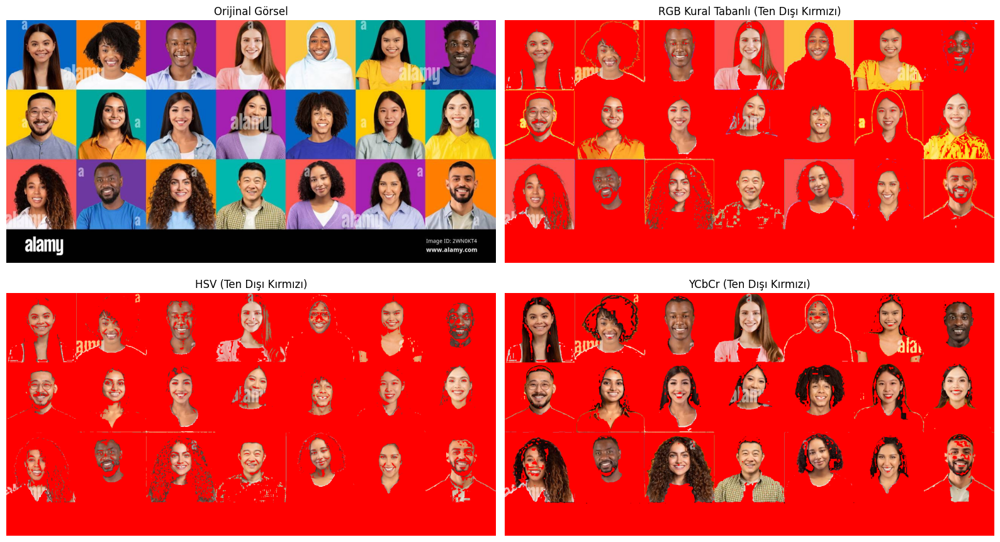

In [51]:
# --- METOD 3: YCbCr Renk Uzayında Ten Tespiti ---
if 'img' in globals() and img is not None:
    img_ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)   # kanal sırası: Y, Cr, Cb

    # Chai & Ngan (1999) ten aralıkları — Y (parlaklık) kanalı kasıtlı olarak kullanılmıyor
    lower_ycrcb = np.array([0, 133, 77], dtype=np.uint8)
    upper_ycrcb = np.array([255, 173, 127], dtype=np.uint8)
    ycrcb_skin_mask = cv2.inRange(img_ycrcb, lower_ycrcb, upper_ycrcb)

    # Ten olmayan bölgeleri saf kırmızı yapalım (BGR = [0, 0, 255])
    img_ycrcb_segmented = img.copy()
    img_ycrcb_segmented[ycrcb_skin_mask == 0] = [0, 0, 255]
    cv2.imwrite('skin_detected_ycbcr.bmp', img_ycrcb_segmented)
    print("[BAŞARILI] YCbCr segmentasyonu 'skin_detected_ycbcr.bmp' olarak kaydedildi.")

    # Üç yöntemin ten olarak işaretlediği piksel oranları
    toplam = img.shape[0] * img.shape[1]
    print(f"Ten olarak işaretlenen piksel oranı -> RGB: {rgb_skin_mask.sum()/toplam:.2%} | "
          f"HSV: {(hsv_skin_mask > 0).sum()/toplam:.2%} | YCbCr: {(ycrcb_skin_mask > 0).sum()/toplam:.2%}")

    # Karşılaştırmalı görselleştirme (en-boy oranı korunarak)
    fig, axes = plt.subplots(2, 2, figsize=(16, 9))
    paneller = [(img, "Orijinal Görsel"),
                (img_rgb_segmented, "RGB Kural Tabanlı (Ten Dışı Kırmızı)"),
                (img_hsv_segmented, "HSV (Ten Dışı Kırmızı)"),
                (img_ycrcb_segmented, "YCbCr (Ten Dışı Kırmızı)")]
    for ax, (im, baslik) in zip(axes.ravel(), paneller):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(baslik)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("[HATA] Önce görseli yükleyen hücreyi çalıştırın!")

## Haftalık Görev 1: Web Kamerasında Hareket Tabanlı ROI ve ROI İçinde Ten Tespiti

**Görev:** OpenCV ile web kamerasını açmak; peş peşe gelen çerçevelerde hareketli bölgeyi tespit etmek (yeterince piksel hareket ettiyse); geri kalan kısmı arka plan olarak belirlemek ve **sadece ROI içinde** çalışacak şekilde insan tenini tespit edip renklendirmek.

**Yöntem:**
1. **Ön işleme:** Her çerçeve gri tonlamaya çevrilir ve 11×11 Gauss filtresiyle yumuşatılır (kamera gürültüsünü bastırmak için).
2. **Ardışık çerçeve farkı (frame differencing):** `D(x,y) = |I_t(x,y) − I_{t−1}(x,y)|`; `D > 20` olan pikseller "değişmiş" kabul edilir, maske genişletme (dilation) ile birleştirilir.
3. **"Yeterince hareket" kontrolü:** Değişen piksel sayısı `MIN_HAREKET_PIKSEL = 1500`'ü aşmazsa çerçevenin tamamı arka plandır (küçük titreşim/gürültü yok sayılır).
4. **ROI:** Alanı ≥ 800 piksel olan hareket bölgelerinin sınırlayıcı kutuları (15 px pay ile) ROI olarak alınır; çakışan kutular birleştirilir. **ROI dışındaki tüm pikseller arka plandır** ve çıktıda gri tonlu/karartılmış gösterilir.
5. **ROI içinde ten tespiti:** Görev 5'teki en başarılı yöntem olan **YCrCb** eşikleri (133 ≤ Cr ≤ 173, 77 ≤ Cb ≤ 127) yalnızca ROI pikselleri üzerinde uygulanır, morfolojik açma/kapama ile temizlenir ve ten pikselleri **macenta** ile renklendirilir.

Böylece hareket etmeyen ten renkli nesneler (ör. arka plandaki ahşap, duvar) hiç işlenmez ve ten tespitinin maliyeti tüm çerçeve yerine yalnızca ROI kadar olur.

> **Önemli — kamera simülasyonu:** Colab sunucusunda fiziksel kamera yoktur ve bu çalışma kamerasız bir bilgisayarda yapılmıştır. Bu nedenle:
> 1. İlk hücre, gerçek zamanlı OpenCV sürümünü `webcam_hareket_ten.py` dosyasına yazar. Kameralı bir bilgisayarda `python webcam_hareket_ten.py` ile web kamerası (`cv2.VideoCapture(0)`), `python webcam_hareket_ten.py video.mp4` ile bir video dosyası kullanılır.
> 2. İkinci hücre bir **sanal web kamerası** oluşturur: Görev 5'teki görsel sabit sahne olarak kullanılır, görselden otomatik seçilen bir yüz kameranın önünde hareket eden kişi gibi sahnede dolaştırılır; her kareye sensör gürültüsü ve parlaklık titremesi eklenir. Bu kayıt `cv2.VideoCapture('sanal_kamera.mp4')` ile tıpkı bir kamera gibi kare kare okunur ve aynı fonksiyonlarla işlenir. Sahnedeki diğer yüzler **hareketsiz ten bölgeleri** olduğundan, yöntemin yalnızca ROI içinde çalıştığı doğrudan gözlemlenebilir.

In [60]:
%%writefile webcam_hareket_ten.py
"""
Haftalık Görev 1 — Web kamerası ile hareket tabanlı ROI ve ROI içinde ten tespiti
--------------------------------------------------------------------------------
1) OpenCV ile web kamerası açılır (cv2.VideoCapture).
2) Peş peşe gelen iki çerçevenin farkı (frame differencing) alınır.
3) Değişen piksel sayısı eşiği aşarsa (yeterince piksel hareket ettiyse) hareketli bölgeler ROI olarak alınır.
4) ROI dışında kalan her şey ARKA PLAN kabul edilir (görselde gri tonlu ve karartılmış gösterilir).
5) Ten tespiti SADECE ROI pikselleri üzerinde (YCrCb uzayında) yapılır ve ten pikselleri renklendirilir.

Yerel bilgisayarda çalıştırma:  python webcam_hareket_ten.py              (web kamerası, çıkmak için 'q')
Kamera yoksa (simülasyon):      python webcam_hareket_ten.py video.mp4    (aynı algoritma bir video dosyasında)
"""
import time
import cv2
import numpy as np

# ---------------- Parametreler ----------------
FARK_ESIGI = 20            # iki çerçeve arasındaki gri seviye farkı bu değerden büyükse piksel "değişmiş" sayılır
MIN_HAREKET_PIKSEL = 1500  # "yeterince piksel hareket etti" eşiği (320x240 için ~%2)
MIN_ROI_ALANI = 800        # bundan küçük hareket bölgeleri gürültü kabul edilir
ROI_PAY = 15               # ROI kutusunu her yönden bu kadar piksel genişlet
TEN_RENGI = (255, 0, 255)  # ten piksellerinin boyanacağı renk (BGR: macenta)

# Chai & Ngan (1999) YCrCb ten aralıkları (Görev 5'te kullanılanla aynı)
YCRCB_ALT = np.array([0, 133, 77], dtype=np.uint8)
YCRCB_UST = np.array([255, 173, 127], dtype=np.uint8)


def on_isle(frame_bgr):
    """Gri tonlama + Gauss bulanıklaştırma (kamera gürültüsünü azaltır)."""
    gri = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)
    return cv2.GaussianBlur(gri, (11, 11), 0)


def hareket_maskesi(onceki_gri, simdiki_gri):
    """Ardışık iki çerçevenin mutlak farkından ikili hareket maskesi üretir."""
    fark = cv2.absdiff(onceki_gri, simdiki_gri)
    _, maske = cv2.threshold(fark, FARK_ESIGI, 255, cv2.THRESH_BINARY)
    maske = cv2.dilate(maske, None, iterations=3)   # parçalı bölgeleri birleştir
    return maske


def roi_kutulari(maske):
    """Hareket maskesindeki yeterince büyük bölgelerin sınırlayıcı kutularını döndürür."""
    h, w = maske.shape
    konturlar, _ = cv2.findContours(maske, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    kutular = []
    for k in konturlar:
        if cv2.contourArea(k) < MIN_ROI_ALANI:
            continue
        x, y, bw, bh = cv2.boundingRect(k)
        x0, y0 = max(0, x - ROI_PAY), max(0, y - ROI_PAY)
        x1, y1 = min(w, x + bw + ROI_PAY), min(h, y + bh + ROI_PAY)
        kutular.append((x0, y0, x1, y1))
    # Ardışık çerçeve farkı bir nesnenin ön ve arka kenarını ayrı parçalar halinde verir;
    # çakışan/değen kutuları tek bir ROI'de birleştiriyoruz.
    birlesti = True
    while birlesti:
        birlesti = False
        for i in range(len(kutular)):
            for j in range(i + 1, len(kutular)):
                a, b = kutular[i], kutular[j]
                if a[0] <= b[2] and b[0] <= a[2] and a[1] <= b[3] and b[1] <= a[3]:
                    kutular[i] = (min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3]))
                    del kutular[j]
                    birlesti = True
                    break
            if birlesti:
                break
    return kutular


def roi_icinde_ten(roi_bgr):
    """Ten maskesini YALNIZCA verilen ROI parçası üzerinde hesaplar."""
    ycrcb = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2YCrCb)
    ten = cv2.inRange(ycrcb, YCRCB_ALT, YCRCB_UST)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    ten = cv2.morphologyEx(ten, cv2.MORPH_OPEN, k)    # küçük gürültüleri temizle
    ten = cv2.morphologyEx(ten, cv2.MORPH_CLOSE, k)   # küçük boşlukları doldur
    return ten


def hareket_ve_ten_isle(onceki_gri, frame_bgr):
    """
    Bir çerçeveyi işler.
    Döndürür: (çıktı görüntüsü, şimdiki gri çerçeve, hareket maskesi, ROI kutuları, bilgi sözlüğü)
    """
    simdiki_gri = on_isle(frame_bgr)
    h, w = simdiki_gri.shape

    # Arka plan görünümü: gri tonlu ve karartılmış
    gri3 = cv2.cvtColor(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR)
    cikti = (gri3 * 0.5).astype(np.uint8)

    maske = np.zeros((h, w), np.uint8)
    kutular, ten_piksel, roi_piksel = [], 0, 0
    if onceki_gri is not None:
        maske = hareket_maskesi(onceki_gri, simdiki_gri)
        hareketli = cv2.countNonZero(maske)
        if hareketli >= MIN_HAREKET_PIKSEL:            # yeterince piksel hareket ettiyse
            kutular = roi_kutulari(maske)
    else:
        hareketli = 0

    for (x0, y0, x1, y1) in kutular:
        roi = frame_bgr[y0:y1, x0:x1]
        ten = roi_icinde_ten(roi)                      # ten tespiti sadece ROI içinde
        roi_cikti = roi.copy()                         # ROI orijinal renkleriyle gösterilir
        roi_cikti[ten > 0] = (0.4 * roi[ten > 0] + 0.6 * np.array(TEN_RENGI)).astype(np.uint8)
        cikti[y0:y1, x0:x1] = roi_cikti
        cv2.rectangle(cikti, (x0, y0), (x1 - 1, y1 - 1), (0, 255, 0), 2)
        ten_piksel += cv2.countNonZero(ten)
        roi_piksel += (x1 - x0) * (y1 - y0)

    bilgi = {"hareketli_piksel": hareketli, "roi_sayisi": len(kutular),
             "roi_orani": roi_piksel / (h * w), "ten_piksel": ten_piksel}
    durum = "HAREKET VAR" if kutular else "hareket yok (tumu arka plan)"
    cv2.putText(cikti, f"{durum} | degisen piksel: {hareketli} | ROI: {len(kutular)}",
                (8, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1, cv2.LINE_AA)
    return cikti, simdiki_gri, maske, kutular, bilgi


def main(kaynak=0):
    """kaynak = 0 -> web kamerası; kaynak = 'video.mp4' -> kamera yerine video dosyası (simülasyon)."""
    cap = cv2.VideoCapture(kaynak)
    if not cap.isOpened():
        print("[HATA] Web kamerası / video açılamadı!")
        return
    bekleme = 1 if isinstance(kaynak, int) else 100   # video dosyasında ~10 fps oynatım
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)
    onceki_gri, t_onceki = None, time.perf_counter()
    print("[BİLGİ] Kamera açıldı. Çıkmak için 'q' tuşuna basın.")
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.resize(frame, (640, 480))
        cikti, onceki_gri, maske, kutular, bilgi = hareket_ve_ten_isle(onceki_gri, frame)
        t = time.perf_counter()
        fps = 1.0 / max(t - t_onceki, 1e-6)
        t_onceki = t
        cv2.putText(cikti, f"FPS: {fps:.1f}", (8, 470), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
        cv2.imshow("Orijinal", frame)
        cv2.imshow("Hareket maskesi (ardisik cerceve farki)", maske)
        cv2.imshow("Sonuc: arka plan gri, ROI icinde ten renklendirildi", cikti)
        if cv2.waitKey(bekleme) & 0xFF == ord('q'):
            break
    cap.release()
    cv2.destroyAllWindows()


if __name__ == "__main__":
    import sys
    main(sys.argv[1] if len(sys.argv) > 1 else 0)

Overwriting webcam_hareket_ten.py


[BAŞARILI] Sanal kamera kaydı oluşturuldu: sanal_kamera.mp4 (72 kare, 640x480, 10 fps)
 SANAL KAMERA — HAREKET TABANLI ROI + ROI İÇİNDE TEN TESPİTİ
İşlenen kare sayısı                       : 72
Hareket tespit edilen kare                : 57  (beklenen: kişinin belirdiği/hareket ettiği/çıktığı 57 kare)
Hareketsiz başlangıç/bitiş karelerinde ROI: 0 (beklenen: 0)
Sahnedeki hareketsiz ten pikseli          : 102,874 (ROI dışında kalanlar hiç işlenmez)
Ortalama ROI alanı / kare                 : %11.9 (geri kalan %88.1 arka plan)
Ten tespiti süresi — sadece ROI           : 0.304 ms
Ten tespiti süresi — tüm kare             : 1.458 ms


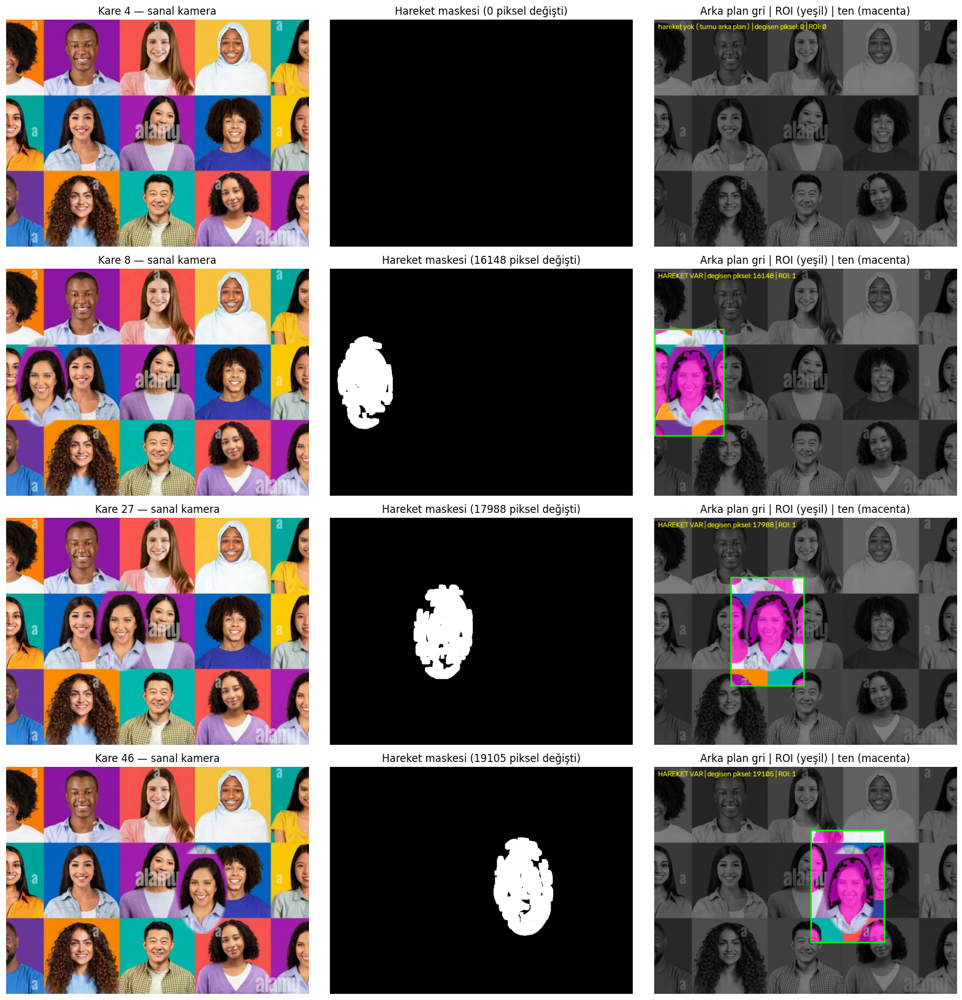

[BAŞARILI] Sonuç 'sanal_kamera_sonuc.mp4' ve 'sanal_kamera_sonuc.gif' olarak kaydedildi.


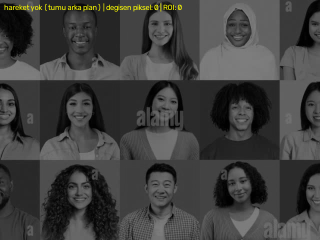

In [62]:
# --- Sanal Web Kamerası: kamera olmadan aynı OpenCV akışının simülasyonu ---
# Fiziksel kamera olmadığı için Görev 5'teki görselden (görüntüişleme9.jpg) 640x480, 10 fps'lik
# bir "kamera kaydı" üretiyoruz ve onu cv2.VideoCapture ile tıpkı bir web kamerası gibi okuyoruz.
#   * Sahne sabittir (sabit kamera); görseldeki yüzler HAREKETSİZ ten bölgeleridir.
#   * Görselden otomatik seçilen bir yüz, kameranın önünde hareket eden "kişi" olarak sahnede dolaşır.
#   * Gerçek kamerayı taklit etmek için her kareye sensör gürültüsü ve hafif parlaklık titremesi eklenir.
#   * İlk ve son 8 karede kimse hareket etmez -> tüm çerçeve arka plan olmalıdır.
import importlib, time
import numpy as np, cv2
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display, Image as IPyImage
import webcam_hareket_ten as wht
importlib.reload(wht)

W, H, FPS, N_KARE = 640, 480, 10, 72
rng = np.random.default_rng(42)

# 1) Sabit sahne (arka plan): görseli 480 px yüksekliğe ölçekleyip ortadan 640x480 kırpıyoruz
kaynak = cv2.imread('/content/görüntüişleme9.jpg')
# Görselin altındaki koyu filigran şeridini (stok fotoğraf alt bilgisi) kırpıyoruz
satir_parlaklik = cv2.cvtColor(kaynak, cv2.COLOR_BGR2GRAY).mean(axis=1)
alt = len(satir_parlaklik)
while alt > kaynak.shape[0] // 2 and satir_parlaklik[alt - 1] < 50:
    alt -= 1
kaynak = kaynak[:alt]
olcek = H / kaynak.shape[0]
kaynak = cv2.resize(kaynak, (int(round(kaynak.shape[1] * olcek)), H), interpolation=cv2.INTER_AREA)
x_bas = (kaynak.shape[1] - W) // 2
sahne = kaynak[:, x_bas:x_bas + W].copy()

# 2) Hareket edecek "kişi": görseldeki en büyük ten bölgesini (bir yüz) otomatik bulup eliptik maske ile kesiyoruz
ten_tum = cv2.inRange(cv2.cvtColor(kaynak, cv2.COLOR_BGR2YCrCb), wht.YCRCB_ALT, wht.YCRCB_UST)
ten_tum = cv2.morphologyEx(ten_tum, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
n, etiket, stat, merkez = cv2.connectedComponentsWithStats(ten_tum)
aday = [i for i in range(1, n) if stat[i, cv2.CC_STAT_AREA] > 1500
        and 0.6 < stat[i, cv2.CC_STAT_HEIGHT] / stat[i, cv2.CC_STAT_WIDTH] < 2.0]
alanlar = [stat[i, cv2.CC_STAT_AREA] for i in aday]
yuz = aday[int(np.argsort(alanlar)[len(alanlar) // 2])]          # tipik (medyan büyüklükte) bir yüz
cx, cy = merkez[yuz]
pw, ph = int(stat[yuz, cv2.CC_STAT_WIDTH] * 1.3), int(stat[yuz, cv2.CC_STAT_HEIGHT] * 1.4)
x0, y0 = int(max(0, cx - pw / 2)), int(max(0, cy - ph / 2))
parca = kaynak[y0:y0 + ph, x0:x0 + pw].copy()
parca = cv2.resize(parca, (110, int(110 * parca.shape[0] / parca.shape[1])))   # ~110 px genişliğinde kişi
ph, pw = parca.shape[:2]
alfa = np.zeros((ph, pw), np.float32)
cv2.ellipse(alfa, (pw // 2, ph // 2), (pw // 2 - 2, ph // 2 - 2), 0, 0, 360, 1.0, -1)
alfa = cv2.GaussianBlur(alfa, (15, 15), 0)[..., None]   # yumuşak kenar

# 3) Sanal kamera kaydını oluşturma (kişi soldan sağa dalgalı bir yol izler)
yazici = cv2.VideoWriter('sanal_kamera.mp4', cv2.VideoWriter_fourcc(*'mp4v'), FPS, (W, H))
for t in range(N_KARE):
    kare = sahne.astype(np.float32)
    if 8 <= t < N_KARE - 8:
        s = (t - 8) / (N_KARE - 17)
        px = int(20 + s * (W - pw - 40))
        py = int((H - ph) / 2 + 0.3 * (H - ph) * np.sin(2 * np.pi * 1.5 * s))
        bolge = kare[py:py + ph, px:px + pw]
        kare[py:py + ph, px:px + pw] = alfa * parca + (1 - alfa) * bolge
    kare = kare * rng.uniform(0.98, 1.02) + rng.normal(0, 3, kare.shape)   # parlaklık titremesi + sensör gürültüsü
    yazici.write(np.clip(kare, 0, 255).astype(np.uint8))
yazici.release()
print(f"[BAŞARILI] Sanal kamera kaydı oluşturuldu: sanal_kamera.mp4 ({N_KARE} kare, {W}x{H}, {FPS} fps)")

# 4) Kaydı web kamerası gibi OpenCV ile açıp kare kare işleme (gerçek kamerada: cv2.VideoCapture(0))
cap = cv2.VideoCapture('sanal_kamera.mp4')
onceki_gri, sonuclar, t_roi, t_tam = None, [], [], []
while True:
    ok, kare = cap.read()
    if not ok:
        break
    cikti, onceki_gri, maske, kutular, bilgi = wht.hareket_ve_ten_isle(onceki_gri, kare)
    sonuclar.append((kare, maske, cikti, bilgi))
    if kutular:
        t0 = time.perf_counter()
        for (a0, b0, a1, b1) in kutular:
            wht.roi_icinde_ten(kare[b0:b1, a0:a1])
        t_roi.append(time.perf_counter() - t0)
        t0 = time.perf_counter()
        wht.roi_icinde_ten(kare)
        t_tam.append(time.perf_counter() - t0)
cap.release()

# 5) Özet
hareketli = [i for i, s in enumerate(sonuclar) if s[3]["roi_sayisi"] > 0]
sahne_ten = cv2.inRange(cv2.cvtColor(sahne, cv2.COLOR_BGR2YCrCb), wht.YCRCB_ALT, wht.YCRCB_UST)
print("=" * 72)
print(" SANAL KAMERA — HAREKET TABANLI ROI + ROI İÇİNDE TEN TESPİTİ")
print("=" * 72)
print(f"İşlenen kare sayısı                       : {len(sonuclar)}")
print(f"Hareket tespit edilen kare                : {len(hareketli)}  (beklenen: kişinin belirdiği/hareket ettiği/çıktığı "
      f"{N_KARE - 15} kare)")
print(f"Hareketsiz başlangıç/bitiş karelerinde ROI: "
      f"{sum(s[3]['roi_sayisi'] for s in sonuclar[1:8] + sonuclar[-7:])} (beklenen: 0)")
print(f"Sahnedeki hareketsiz ten pikseli          : {cv2.countNonZero(sahne_ten):,} (ROI dışında kalanlar hiç işlenmez)")
if hareketli:
    ort_roi = np.mean([sonuclar[i][3]['roi_orani'] for i in hareketli])
    print(f"Ortalama ROI alanı / kare                 : %{ort_roi * 100:.1f} (geri kalan %{(1 - ort_roi) * 100:.1f} arka plan)")
    print(f"Ten tespiti süresi — sadece ROI           : {np.mean(t_roi) * 1000:.3f} ms")
    print(f"Ten tespiti süresi — tüm kare             : {np.mean(t_tam) * 1000:.3f} ms")
print("=" * 72)

# 6) Örnek kareler: orijinal | hareket maskesi | sonuç
gosterilecek = [4] + hareketli[::max(1, len(hareketli) // 3)][:3]
fig, axes = plt.subplots(len(gosterilecek), 3, figsize=(16, 4.1 * len(gosterilecek)), squeeze=False)
for satir, i in enumerate(gosterilecek):
    kare, maske, cikti, bilgi = sonuclar[i]
    axes[satir, 0].imshow(cv2.cvtColor(kare, cv2.COLOR_BGR2RGB)); axes[satir, 0].set_title(f"Kare {i} — sanal kamera")
    axes[satir, 1].imshow(maske, cmap="gray"); axes[satir, 1].set_title(f"Hareket maskesi ({bilgi['hareketli_piksel']} piksel değişti)")
    axes[satir, 2].imshow(cv2.cvtColor(cikti, cv2.COLOR_BGR2RGB)); axes[satir, 2].set_title("Arka plan gri | ROI (yeşil) | ten (macenta)")
    for ax in axes[satir]: ax.axis("off")
plt.tight_layout(); plt.show()

# 7) Sonuç videosunu kaydetme + animasyon olarak gösterme
yazici = cv2.VideoWriter('sanal_kamera_sonuc.mp4', cv2.VideoWriter_fourcc(*'mp4v'), FPS, (W, H))
for s in sonuclar:
    yazici.write(s[2])
yazici.release()
# (Not defterinin boyutunu küçük tutmak için GIF'te 320x240 çözünürlük ve her 2. kare kullanılır; tam video .mp4 dosyasındadır)
gif = [PILImage.fromarray(cv2.cvtColor(cv2.resize(s[2], (320, 240)), cv2.COLOR_BGR2RGB)) for s in sonuclar[::2]]
gif[0].save('sanal_kamera_sonuc.gif', save_all=True, append_images=gif[1:], duration=2000 // FPS, loop=0)
print("[BAŞARILI] Sonuç 'sanal_kamera_sonuc.mp4' ve 'sanal_kamera_sonuc.gif' olarak kaydedildi.")
display(IPyImage(filename='sanal_kamera_sonuc.gif'))

## Haftalık Görev 2: Kırmızı Çemberli Trafik İşaretlerinin Tespiti (Renk Uzayları + Hough)

**Veri kümesi:** Kaggle — *Traffic Signs Dataset (Germany, UK, USA)* (`tabishalam0/traffic-signs-dataset-germany-uk-usa`), 16 sınıf, ~2.600 görsel.

**Görsel seçimi:** Veri kümesi farklı arka planlara sahip stok fotoğraflardan oluşur. Bu çalışmada **mavi arka planlı görseller kullanılmamış**, yalnızca **beyaz arka planlı** görseller seçilmiştir. Seçim iki aşamalıdır: (1) otomatik ön filtre — kenar piksellerinin ≥%85'i beyaz ve mavi piksel oranı <%0,5; (2) görsel olarak tek tek kontrol edilerek etiketleme:
- **Pozitif (26 görsel):** kırmızı çemberli işaretler — hız sınırı (30/50/80), girilmez (no entry), U dönüşü yasak.
- **Negatif (19 görsel):** kırmızı çember **içermeyen** işaretler — özellikle zor örnekler: kırmızı sekizgen **STOP**, kırmızı kenarlı **üçgen** uyarı işaretleri, sarı/turuncu işaretler ve ABD tipi dikdörtgen hız sınırı levhaları.

> Not: Veri kümesindeki ülke klasörleri karışıktır (ör. "United_States" klasöründe Avrupa tipi işaretler bulunur), bu yüzden etiketler klasöre göre değil görsel içeriğe göre verilmiştir.

**Yöntem (her renk uzayı için):**
1. Görseli uzun kenarı 400 px olacak şekilde ölçekle.
2. Seçilen renk uzayında (RGB, HSV, CIE Lab, YCrCb) **kırmızı maske** üret + morfolojik kapama.
3. Maskeyi Gauss filtresiyle yumuşatıp **Hough Çember Dönüşümü** (`cv2.HoughCircles`, `HOUGH_GRADIENT`) uygula.
4. **Doğrulama:** (a) aday çemberin 0,75r–1,25r bandında 72 açının ≥%85'inde kırmızı olmalı (halka kapsaması); (b) ilgili kırmızı bileşenin dış konturu, çevreleyen daireyi ≥%91 doldurmalı (daire ≈ 0,95–1,0; STOP sekizgeni ≈ 0,86–0,90; üçgen ≈ 0,5).
5. Karşılaştırma için renk kullanmadan, yalnızca gri seviye görüntüde Hough uygulayan bir **taban çizgisi (baseline)** da test edilmiştir.

100%|██████████| 23.8M/23.8M [00:00<00:00, 68.6MB/s]

Extracting files...


[BİLGİ] Veri kümesi konumu: /root/.cache/kagglehub/datasets/tabishalam0/traffic-signs-dataset-germany-uk-usa/versions/1/dataset
[BAŞARILI] 26 pozitif + 19 negatif görsel 'traffic_signs_white/' klasörüne kopyalandı.


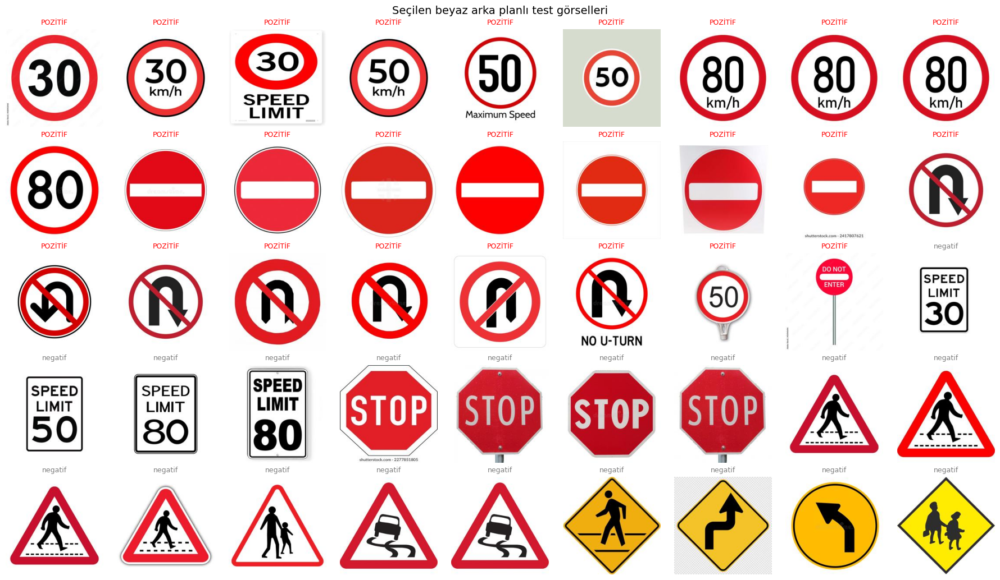

In [53]:
import os, shutil, glob
import kagglehub

# --- 1. Kaggle veri kümesini indirme (herkese açık veri kümesi, API anahtarı gerekmez) ---
ds_root = kagglehub.dataset_download("tabishalam0/traffic-signs-dataset-germany-uk-usa")
ds_dir = os.path.join(ds_root, "dataset")
print("[BİLGİ] Veri kümesi konumu:", ds_dir)

# --- 2. Beyaz arka planlı, elle doğrulanmış görsel listesi ---
secilen = {
    "positive": [  # kırmızı çemberli işaretler
        "speed_limit_30/United_States/000012.jpg", "speed_limit_30/United_States/000017.jpg",
        "speed_limit_30/United_States/000029.jpg", "speed_limit_50/United_States/000034.jpg",
        "speed_limit_50/United_States/000036.jpg", "speed_limit_50/United_States/000045.jpg",
        "speed_limit_80/Germany/000034.jpg", "speed_limit_80/United_Kingdom/000029.jpg",
        "speed_limit_80/United_States/000027.jpg", "speed_limit_80/United_States/000049.jpg",
        "no_entry/Germany/000032.jpg", "no_entry/United_Kingdom/000020.jpg",
        "no_entry/United_Kingdom/000054.jpg", "no_entry/United_States/000009.jpg",
        "no_entry/United_States/000029.jpg", "no_entry/United_States/000039.jpg",
        "no_entry/United_States/000050.jpg", "no_u_turn/Germany/000011.jpg",
        "no_u_turn/Germany/000021.jpg", "no_u_turn/United_Kingdom/000019.jpg",
        "no_u_turn/United_States/000010.jpg", "no_u_turn/United_States/000020.jpg",
        "no_u_turn/United_States/000030.jpg", "no_u_turn/United_States/000036.jpg",
        "speed_limit_50/Germany/000006.jpg", "no_entry/United_States/000001.jpg"],
    "negative": [  # kırmızı çember içermeyen işaretler (zor örnekler dahil)
        "speed_limit_30/United_States/000016.jpg", "speed_limit_50/United_States/000025.jpg",
        "speed_limit_80/United_Kingdom/000007.jpg", "speed_limit_80/United_States/000032.jpg",
        "stop/Germany/000039.jpg", "stop/United_Kingdom/000016.jpg",
        "stop/United_States/000020.jpg", "stop/United_States/000022.jpg",
        "pedestrian_crossing/United_Kingdom/000027.jpg", "pedestrian_crossing/United_Kingdom/000080.jpg",
        "pedestrian_crossing/United_States/000025.jpg", "pedestrian_crossing/United_States/000047.jpg",
        "school_ahead/Germany/000014.jpg", "slippery_road/Germany/000041.jpg",
        "slippery_road/United_Kingdom/000049.jpg", "pedestrian_crossing/United_States/000054.jpg",
        "curve_ahead/Germany/000019.jpg", "curve_ahead/United_States/000017.jpg",
        "school_ahead/Germany/000028.jpg"],
}

# --- 3. Seçilen görselleri çalışma dizinine kopyalama: /content/traffic_signs_white/{positive,negative} ---
out_dir = "traffic_signs_white"
dataset_items = []   # (yerel_yol, etiket)
for etiket, liste in secilen.items():
    os.makedirs(os.path.join(out_dir, etiket), exist_ok=True)
    for rel in liste:
        hedef = os.path.join(out_dir, etiket, rel.replace("/", "_"))
        shutil.copy(os.path.join(ds_dir, rel), hedef)
        dataset_items.append((hedef, etiket))
print(f"[BAŞARILI] {len(secilen['positive'])} pozitif + {len(secilen['negative'])} negatif görsel "
      f"'{out_dir}/' klasörüne kopyalandı.")

# --- 4. Seçilen görsellerin önizlemesi ---
fig, axes = plt.subplots(5, 9, figsize=(18, 10.5))
for ax, (yol, etiket) in zip(axes.ravel(), dataset_items):
    ax.imshow(cv2.cvtColor(cv2.imread(yol), cv2.COLOR_BGR2RGB))
    ax.set_title("POZİTİF" if etiket == "positive" else "negatif",
                 color="red" if etiket == "positive" else "gray", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(dataset_items):]:
    ax.axis("off")
plt.suptitle("Seçilen beyaz arka planlı test görselleri", fontsize=14)
plt.tight_layout()
plt.show()

In [54]:
# --- Kırmızı çember dedektörü: renk uzayı maskesi + Hough + geometrik doğrulama ---
import cv2, numpy as np

def red_mask(img_bgr, space):
    """Kırmızı piksel maskesi (0/255) - seçilen renk uzayına göre."""
    if space == 'RGB':
        B, G, R = [c.astype(np.int16) for c in cv2.split(img_bgr)]
        m = (R > 120) & (R - G > 60) & (R - B > 50)
    elif space == 'HSV':
        hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        m1 = cv2.inRange(hsv, (0, 80, 60), (10, 255, 255))
        m2 = cv2.inRange(hsv, (160, 80, 60), (180, 255, 255))
        m = (m1 | m2) > 0
    elif space == 'Lab':
        lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2Lab)
        m = (lab[..., 1] > 155) & (lab[..., 0] > 40)
    elif space == 'YCrCb':
        ycc = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)
        m = (ycc[..., 1] > 160) & (ycc[..., 2] < 135)
    else:
        raise ValueError(space)
    m = m.astype(np.uint8) * 255
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)

def ring_scores(mask, x, y, r):
    """Aday çemberin üzerinde kırmızı oranı ve açısal kapsama."""
    h, w = mask.shape
    angles = np.linspace(0, 2 * np.pi, 72, endpoint=False)
    hits = np.zeros(72, bool)
    for rr in np.linspace(0.75 * r, 1.25 * r, 6):
        xs = np.clip((x + rr * np.cos(angles)).astype(int), 0, w - 1)
        ys = np.clip((y + rr * np.sin(angles)).astype(int), 0, h - 1)
        hits |= mask[ys, xs] > 0
    return hits.mean()

def contour_fill(mask, x, y, r):
    """Hough adayına karşılık gelen kırmızı bileşenin dış konturu, ideal bir daireyi ne kadar dolduruyor?
    Daire ≈ 0.95-1.0, sekizgen (STOP) ≈ 0.90, üçgen ≈ 0.5."""
    cs, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    best = 0.0
    for c in cs:
        if cv2.contourArea(c) < 50:
            continue
        (cx, cy), rc = cv2.minEnclosingCircle(c)
        if np.hypot(cx - x, cy - y) < 0.3 * r and 0.7 * r < rc < 1.4 * r:
            best = max(best, cv2.contourArea(c) / (np.pi * rc * rc))
    return best

def detect_red_circles(img_bgr, space='HSV', work=400, min_cov=0.85, min_fill=0.91):
    scale = work / max(img_bgr.shape[:2])
    img = cv2.resize(img_bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]
    if space == 'Gray':   # renk bilgisi olmadan, yalnızca Hough (karşılaştırma için)
        src = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5, 5), 1.5)
        mask = None
    else:
        mask = red_mask(img, space)
        src = cv2.GaussianBlur(mask, (7, 7), 2)
    circles = cv2.HoughCircles(src, cv2.HOUGH_GRADIENT, dp=1.2, minDist=min(h, w) / 4,
                               param1=100, param2=20,
                               minRadius=int(min(h, w) * 0.06), maxRadius=int(max(h, w) * 0.55))
    found = []
    if circles is not None:
        for x, y, r in np.round(circles[0]).astype(int):
            if mask is None:
                found.append((x, y, r, 1.0))
                continue
            cov = ring_scores(mask, x, y, r)
            if cov < min_cov:
                continue
            fill = contour_fill(mask, x, y, r)
            if fill >= min_fill:
                found.append((x, y, r, cov))
    # orijinal görüntü koordinatlarına geri ölçekle
    found = [(int(x / scale), int(y / scale), int(r / scale), c) for x, y, r, c in found]
    return found, mask

In [55]:
import time
import pandas as pd

# --- Tüm renk uzaylarında görsel bazlı değerlendirme (pozitif = kırmızı çemberli işaret) ---
uzaylar = ["Gray", "RGB", "HSV", "Lab", "YCrCb"]
tahminler = {sp: [] for sp in uzaylar}
y_true_ts = [etiket == "positive" for _, etiket in dataset_items]
sureler = {}
for sp in uzaylar:
    t0 = time.perf_counter()
    for yol, _ in dataset_items:
        det, _ = detect_red_circles(cv2.imread(yol), sp)
        tahminler[sp].append(len(det) > 0)
    sureler[sp] = (time.perf_counter() - t0) / len(dataset_items) * 1000

satirlar = []
for sp in uzaylar:
    yp = np.array(tahminler[sp]); yt = np.array(y_true_ts)
    tp = int((yp & yt).sum()); fp = int((yp & ~yt).sum()); fn = int((~yp & yt).sum()); tn = int((~yp & ~yt).sum())
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    satirlar.append({"Renk uzayı": "Gray (renksiz Hough)" if sp == "Gray" else sp,
                     "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                     "Doğruluk": (tp + tn) / len(yt), "Hassasiyet": P, "Duyarlılık": R,
                     "F1": 2 * P * R / (P + R) if P + R else 0.0,
                     "Süre (ms/görsel)": sureler[sp]})
ts_tablo = pd.DataFrame(satirlar).set_index("Renk uzayı")
print("=" * 100)
print(" KIRMIZI ÇEMBERLİ TRAFİK İŞARETİ TESPİTİ — 26 pozitif / 19 negatif beyaz arka planlı görsel")
print("=" * 100)
print(ts_tablo.round(3).to_string())
print("=" * 100)
ts_tablo.round(4).to_csv("trafik_isareti_sonuclar.csv")

# Hatalı sınıflandırılan görseller
for sp in uzaylar[1:]:
    hatalar = [(os.path.basename(y), "FN" if e == "positive" else "FP")
               for (y, e), p in zip(dataset_items, tahminler[sp]) if p != (e == "positive")]
    print(f"{sp:6s} hatalar: {hatalar}")

 KIRMIZI ÇEMBERLİ TRAFİK İŞARETİ TESPİTİ — 26 pozitif / 19 negatif beyaz arka planlı görsel
                      TP  FP  FN  TN  Doğruluk  Hassasiyet  Duyarlılık     F1  Süre (ms/görsel)
Renk uzayı                                                                                     
Gray (renksiz Hough)  26  19   0   0     0.578       0.578       1.000  0.732           103.674
RGB                   25   1   1  18     0.956       0.962       0.962  0.962            24.810
HSV                   25   0   1  19     0.978       1.000       0.962  0.980            19.365
Lab                   24   0   2  19     0.956       1.000       0.923  0.960            19.646
YCrCb                 25   1   1  18     0.956       0.962       0.962  0.962            23.604
RGB    hatalar: [('speed_limit_30_United_States_000029.jpg', 'FN'), ('curve_ahead_United_States_000017.jpg', 'FP')]
HSV    hatalar: [('speed_limit_30_United_States_000029.jpg', 'FN')]
Lab    hatalar: [('speed_limit_30_United_States_0000

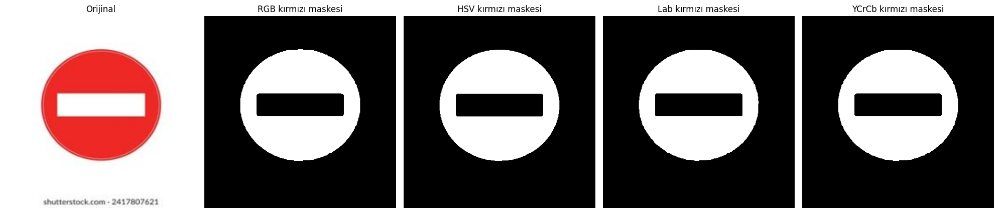

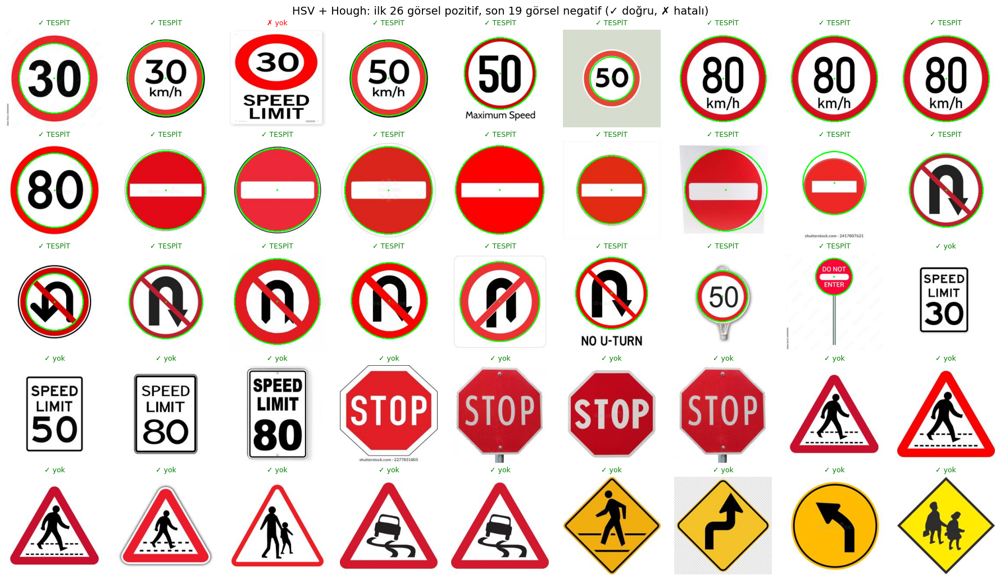

[BAŞARILI] İşaretlenmiş görseller 'trafik_tespit_sonuclari/' klasörüne kaydedildi.


In [56]:
# --- 1. Örnek bir görsel üzerinde renk uzaylarına göre kırmızı maskeler ---
ornek = cv2.imread(dataset_items[16][0])          # gölgeli 3B girilmez işareti (Lab bu görselde başarısız)
ornek_k = cv2.resize(ornek, None, fx=400 / max(ornek.shape[:2]), fy=400 / max(ornek.shape[:2]))
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
axes[0].imshow(cv2.cvtColor(ornek_k, cv2.COLOR_BGR2RGB)); axes[0].set_title("Orijinal")
for ax, sp in zip(axes[1:], ["RGB", "HSV", "Lab", "YCrCb"]):
    ax.imshow(red_mask(ornek_k, sp), cmap="gray"); ax.set_title(f"{sp} kırmızı maskesi")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# --- 2. HSV + Hough tespit sonuçları (yeşil: tespit edilen çember) ---
os.makedirs("trafik_tespit_sonuclari", exist_ok=True)
fig, axes = plt.subplots(5, 9, figsize=(18, 10.5))
for ax, (yol, etiket) in zip(axes.ravel(), dataset_items):
    im = cv2.imread(yol)
    det, _ = detect_red_circles(im, "HSV")
    cizim = im.copy()
    kal = max(2, im.shape[1] // 100)
    for x, y, r, _ in det:
        cv2.circle(cizim, (x, y), r, (0, 255, 0), kal)
        cv2.circle(cizim, (x, y), kal, (0, 255, 0), -1)
    cv2.imwrite(os.path.join("trafik_tespit_sonuclari", os.path.basename(yol)), cizim)
    dogru = (len(det) > 0) == (etiket == "positive")
    ax.imshow(cv2.cvtColor(cizim, cv2.COLOR_BGR2RGB))
    ax.set_title(("✓ " if dogru else "✗ ") + ("TESPİT" if det else "yok"),
                 color="green" if dogru else "red", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(dataset_items):]:
    ax.axis("off")
plt.suptitle("HSV + Hough: ilk 26 görsel pozitif, son 19 görsel negatif (✓ doğru, ✗ hatalı)", fontsize=14)
plt.tight_layout(); plt.show()
print("[BAŞARILI] İşaretlenmiş görseller 'trafik_tespit_sonuclari/' klasörüne kaydedildi.")

### Sonuçlar ve Değerlendirme

**Görev 5 (ten segmentasyonu):** Aynı görselde RGB kuralı piksellerin %27,06'sını, HSV %15,79'unu, YCbCr ise %27,91'ini ten olarak işaretlemiştir. Görsel karşılaştırmada **YCbCr**, koyu tenler dahil farklı ten tonlarındaki yüzlerin neredeyse tamamını korumuştur (saç ve bej kıyafetlerde bazı yanlış pozitiflerle). **HSV**, dar doygunluk aralığı nedeniyle özellikle koyu tenli yüzlerin büyük kısmını kaçırmıştır. **RGB** kuralı ise sarı/turuncu arka plan panellerini de ten saymıştır. Bu problem için en uygun renk uzayı YCbCr'dir; bu yüzden Haftalık Görev 1'de YCbCr kullanılmıştır.

**Haftalık Görev 1 (web kamerası — sanal kamera ile simülasyon):** Fiziksel kamera olmadığı için sabit bir sahne ve bu sahnede hareket eden bir yüzden oluşan 72 karelik sanal kamera kaydı `cv2.VideoCapture` ile okunmuştur. Hareket, kişinin belirdiği/hareket ettiği/çıktığı 57 karenin tamamında tespit edilmiş; hareketsiz başlangıç ve bitiş karelerinde hiç ROI oluşmamıştır (tüm kare arka plan). ROI ortalama olarak karenin %11,9'u kadardır; ten tespiti yalnızca ROI'de 0,30 ms, tüm karede 1,46 ms sürmüştür (≈4,8 kat; süreler çalıştırmadan çalıştırmaya biraz değişir). Sahnedeki hareketsiz yüzler (102.874 ten pikseli) ROI dışında kaldıkları sürece renklendirilmemiştir. Sınırlamalar: ROI dikdörtgen olduğu için kutunun içine düşen hareketsiz ten parçaları da renklendirilir; çerçeve farkı nesnenin yalnızca hareket eden kısmını verir, duran bir el arka plana karışır; sonuçlar gerçek kamera yerine sentetik bir kayıtla elde edilmiştir (gerçek kamera için `python webcam_hareket_ten.py`).

**Haftalık Görev 2 (kırmızı çemberli trafik işaretleri):**

| Renk uzayı | Doğruluk | Hassasiyet | Duyarlılık | F1 |
|---|---|---|---|---|
| Gray (renksiz Hough) | 0,578 | 0,578 | 1,000 | 0,732 |
| RGB | 0,956 | 0,962 | 0,962 | 0,962 |
| **HSV** | **0,978** | **1,000** | **0,962** | **0,980** |
| CIE Lab | 0,956 | 1,000 | 0,923 | 0,960 |
| YCrCb | 0,956 | 0,962 | 0,962 | 0,962 |

- Renk bilgisi olmadan Hough dönüşümü **her** görselde (STOP, üçgenler, dikdörtgen levhalar) çember bulmuştur → renk ön filtresi zorunludur.
- **HSV** en iyi sonucu vermiştir: Hue kanalı kırmızıyı parlaklıktan bağımsız ayırır. RGB ve YCrCb, turuncu bir uyarı levhasını kırmızı saymıştır (1 yanlış pozitif).
- STOP sekizgenleri, Hough'un bulduğu adayın kontur doluluk oranı (≈0,86–0,90 < 0,91) ile elenmiştir.
- Tüm renk uzaylarında kaçırılan ortak görsel, kırmızı halkaya bitişik kırmızı "SPEED LIMIT" yazısı olan levhadır (yazı, konturu daireden saptırır).
- **Not:** Eşikler bu 45 görsellik küçük set üzerinde ayarlandığı için skorlar iyimserdir; mavi gökyüzü veya karmaşık arka planlı görsellerde başarı düşebilir.